# 11 · Test the useful invariances

Four clean arrangements serve as fixed gallery prototypes. For each prototype, generate 24 independent perturbation trajectories. Every trajectory has clean, whole-cell shift, subcell shift, quarter-turn and combined shift/rotation/sign/noise views. The recognition label is arrangement modulo translation and quarter turns. Absolute location, contrast sign and absolute orientation are intentionally irrelevant to this label.

## Setup
Stage 2 holds the motif inventory fixed and changes spatial organization.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.fft import dctn
from observables.core import moments,relative_distance
from observables.images import tiled_orientation
from observables.spatial import *
OUT=ROOT/'results'/'stage2'
OUT.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'figure.figsize':(8,3.8),'figure.dpi':110,
 'figure.constrained_layout.use':True,'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
images={name:mosaic(name) for name in LAYOUTS}
gallery=[representations(image) for image in images.values()]

In [3]:
from observables.stage2 import ensure,CONDITIONS
queries,summary=ensure()
table=summary.pivot(index='metric',columns='condition',values='accuracy')[list(CONDITIONS)]
display(table.round(3))
print('Fixed prototypes:',len(LAYOUTS),'· independent perturbation trajectories:',queries[['layout','source']].drop_duplicates().shape[0])
print('Queries per trajectory:',len(CONDITIONS),'· metrics:',queries.metric.nunique())

condition,clean,cell shift,pixel shift,quarter turn,shift rotation noise
metric,,,,,
Q_correlation,1.00,1.000,1.000,1.000,1.000
global_Q,0.25,0.250,0.250,0.250,0.250
local_Q_16,1.00,0.479,0.669,0.388,0.229
local_Q_2,0.50,0.370,0.500,0.438,0.250
local_Q_4,0.75,0.510,0.708,0.667,0.312
local_Q_8,1.00,0.479,0.669,0.388,0.250
patch_Q,0.25,0.250,0.250,0.250,0.250
patch_mean,0.25,0.250,0.250,0.250,0.250
pixels,1.00,0.479,0.391,0.388,0.333


Fixed prototypes: 4 · independent perturbation trajectories: 96
Queries per trajectory: 5 · metrics: 12


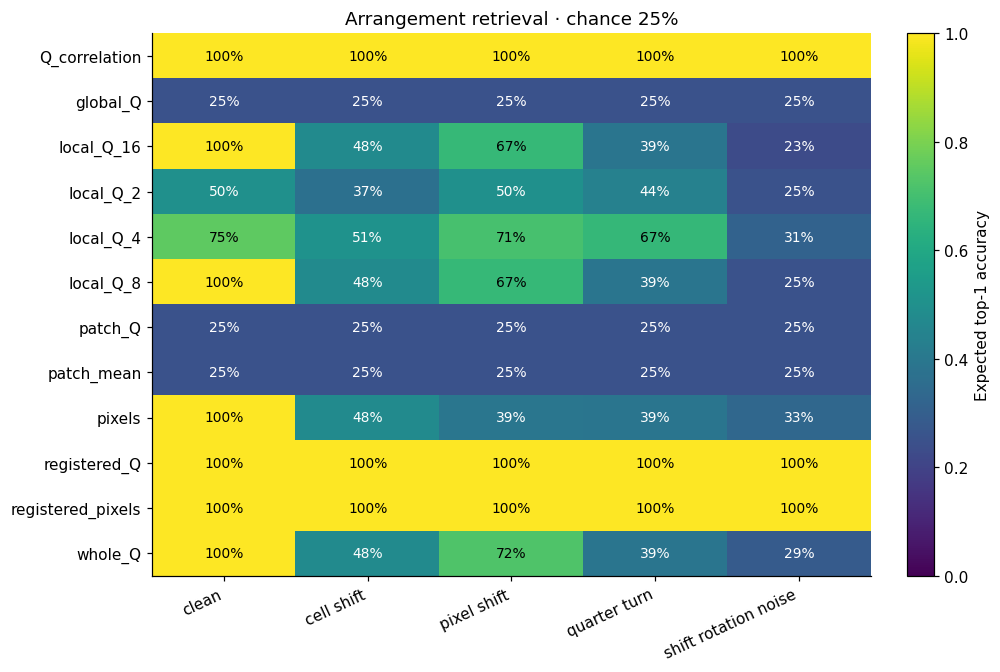

In [3]:
fig,ax=plt.subplots(figsize=(9,6))
im=ax.imshow(table,vmin=0,vmax=1,cmap='viridis',aspect='auto')
ax.set_xticks(range(len(table.columns)),table.columns,rotation=25,ha='right')
ax.set_yticks(range(len(table)),table.index)
for i in range(len(table)):
    for j in range(len(table.columns)):
        value=table.iloc[i,j]
        ax.text(j,i,f'{100*value:.0f}%',ha='center',va='center',color='black' if value>.65 else 'white',fontsize=9)
ax.set_title('Arrangement retrieval · chance 25%')
fig.colorbar(im,ax=ax,label='Expected top-1 accuracy')
show('11_retrieval_matrix')

## Estimate uncertainty at the appropriate unit
Intervals resample the 24 perturbation trajectories independently within each of the four prototype strata. Every condition and metric uses the same resampling indices. The intervals quantify perturbation variability for these four fixed arrangements. They give no estimate of generalization to new motif inventories or new arrangement families. Identical clean copies are controls and supply no extra independent image content.

In [5]:
selected=summary[summary.condition=='shift rotation noise'].set_index('metric')
display(selected[['accuracy','low95','high95']].round(3))
z=queries[queries.condition=='shift rotation noise'].pivot(index=['layout','source'],columns='metric',values='accuracy').sort_index()
n=z.index.get_level_values('source').nunique()
idx=(np.random.default_rng(57).integers(n,size=(5000,4,n))+np.arange(4)[None,:,None]*n).reshape(5000,-1)
pairs=[]
for left,right in [('Q_correlation','local_Q_8'),('registered_Q','local_Q_8'),('registered_Q','registered_pixels')]:
    delta=(z[left]-z[right]).to_numpy()
    lo,hi=np.quantile(delta[idx].mean(1),[.025,.975])
    pairs.append((left,right,delta.mean(),lo,hi))
paired=pd.DataFrame(pairs,columns=['left','right','difference','low95','high95'])
display(paired.round(3));paired.to_csv(OUT/'paired_differences.csv',index=False)

,accuracy,low95,high95
metric,,,
Q_correlation,1.000,1.000,1.000
global_Q,0.250,0.250,0.250
local_Q_16,0.229,0.146,0.312
local_Q_2,0.250,0.250,0.250
local_Q_4,0.312,0.250,0.375
local_Q_8,0.250,0.167,0.333
patch_Q,0.250,0.250,0.250
patch_mean,0.250,0.250,0.250
pixels,0.333,0.229,0.417


,left,right,difference,low95,high95
0,Q_correlation,local_Q_8,0.75,0.667,0.833
1,registered_Q,local_Q_8,0.75,0.667,0.833
2,registered_Q,registered_pixels,0.00,0.000,0.000


## Interpret representation and decision together
The clean comparisons expose an exact limitation of permutation-invariant pooled moments. The displacement conditions test the coordinate dependence of local descriptors. The orbit comparisons deliberately change the equivalence relation: all translated and quarter-turned versions become one object for the decision rule.

This alignment would be inappropriate if a label depended on absolute location or absolute orientation. Pixel registration is a strong control using the same allowed nuisance group. A successful Q-field score must be assessed against that control as well as against unregistered pixels and pooled descriptors.

In [7]:
assert np.isclose(table.loc['patch_mean','clean'],.25)
assert np.isclose(table.loc['patch_Q','clean'],.25)
assert np.isclose(table.loc['global_Q','clean'],.25)
for name in ['registered_pixels','registered_Q','Q_correlation']:
    assert np.isclose(table.loc[name,'clean'],1)
print('Pooled-moment collision and clean arrangement-retrieval checks passed.')

Pooled-moment collision and clean arrangement-retrieval checks passed.


## Next stage
1. Add new motif inventories and nonperiodic boundaries to test transfer beyond this controlled quartet.
2. Construct arrangements with equal Q-field pair correlations to compare third-order or mixed position–orientation observables.
3. Compare vector correlations, their scalar traces and local angular orders under the same information budget.
4. Introduce a frozen learned patch encoder and a whole-image embedding while retaining exact synthetic interventions. Quantify what survives encoding before selecting profile components.
5. Fit any profile combination on separate development configurations; retain independent test families and compare against registration-aware baselines.

This stage establishes spatial resolving power and the effects of nuisance equivalence. Real-world category or semantic claims require independent evidence.